# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Read data

In [2]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/attrition.csv')
df.head()

,Age,MonthlyIncome,JobSatisfaction,DistanceFromHome,YearsAtCompany,OverTime,Attrition
0,30,15058,3.0,34,13,No,0
1,46,10795,2.0,22,22,Yes,0
2,25,7235,3.0,39,15,Yes,0
3,45,15493,4.0,33,23,No,0
4,37,17421,3.0,11,14,Yes,0


In [3]:
df.shape

(3000, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               3000 non-null   int64  
 1   MonthlyIncome     3000 non-null   int64  
 2   JobSatisfaction   2800 non-null   float64
 3   DistanceFromHome  3000 non-null   int64  
 4   YearsAtCompany    3000 non-null   int64  
 5   OverTime          3000 non-null   object 
 6   Attrition         3000 non-null   int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 164.2+ KB


In [5]:
df.describe()

,Age,MonthlyIncome,JobSatisfaction,DistanceFromHome,YearsAtCompany,Attrition
count,3000.000000,3000.000000,2800.000000,3000.000000,3000.000000,3000.000000
mean,40.464000,12530.414667,2.557143,20.196667,11.989000,0.067667
std,11.052032,11636.242498,1.109068,11.292704,7.220498,0.251215
min,22.000000,3009.000000,1.000000,1.000000,0.000000,0.000000
25%,31.000000,7302.500000,2.000000,11.000000,6.000000,0.000000
50%,40.000000,11584.500000,3.000000,20.000000,12.000000,0.000000
75%,50.000000,15928.750000,4.000000,30.000000,18.000000,0.000000
max,59.000000,148323.000000,4.000000,39.000000,24.000000,1.000000


# Data Visualization

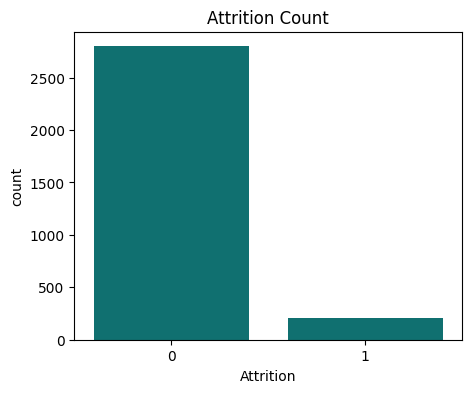

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Attrition', data=df, color='teal')
plt.title('Attrition Count')
plt.show()

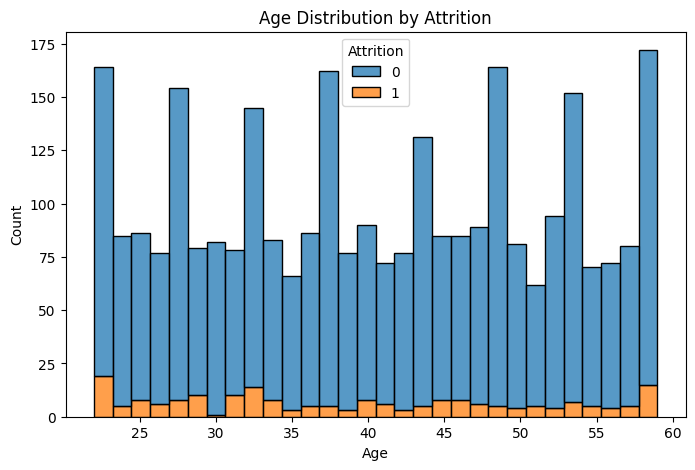

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Attrition', bins=30, multiple='stack')
plt.title('Age Distribution by Attrition')
plt.show()

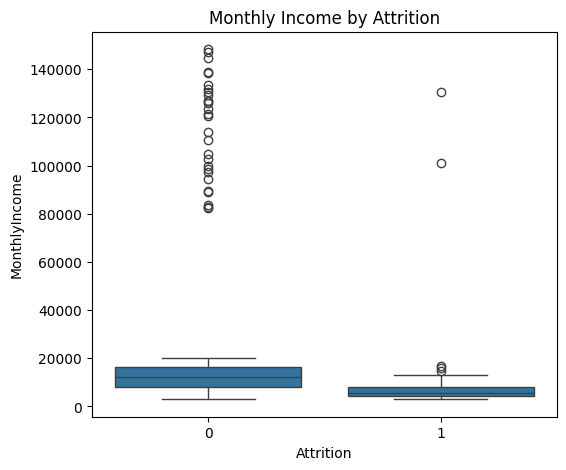

In [8]:
plt.figure(figsize=(6, 5))
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df)
plt.title('Monthly Income by Attrition')
plt.show()

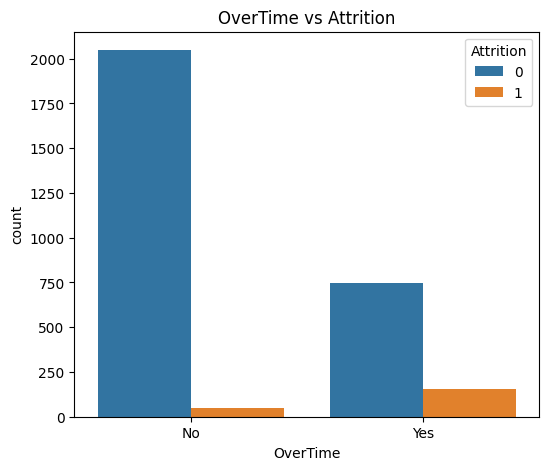

In [9]:
plt.figure(figsize=(6, 5))
sns.countplot(x='OverTime', hue='Attrition', data=df)
plt.title('OverTime vs Attrition')
plt.show()

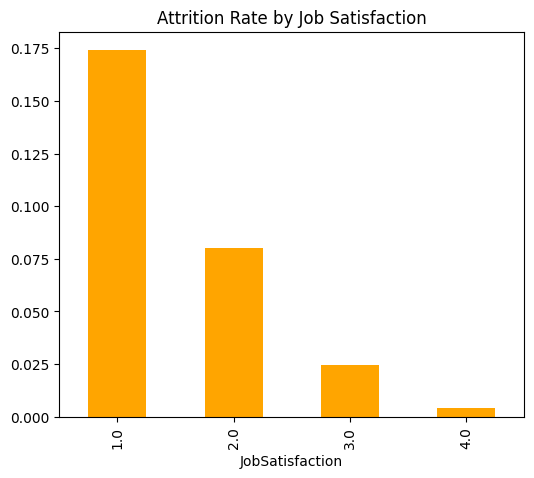

In [10]:
plt.figure(figsize=(6, 5))
df.groupby('JobSatisfaction')['Attrition'].mean().plot(kind='bar', color='orange')
plt.title('Attrition Rate by Job Satisfaction')
plt.show()

# Data Cleaning duplicated

In [11]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)

Number of duplicate rows :  0


# Data Cleaning missing Value

In [12]:
df.isnull().sum().sort_values(ascending=False)

JobSatisfaction     200
Age                   0
MonthlyIncome         0
DistanceFromHome      0
YearsAtCompany        0
OverTime              0
Attrition             0
dtype: int64

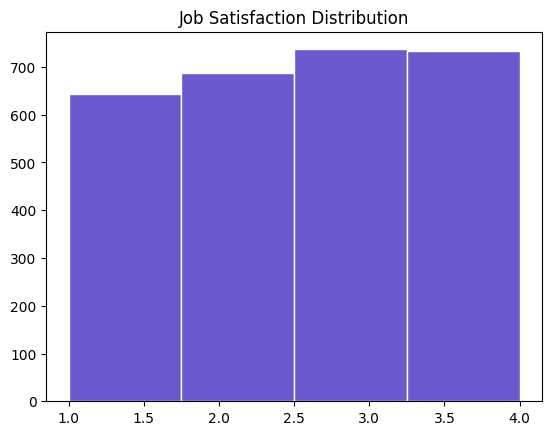

In [13]:
plt.hist(df['JobSatisfaction'].dropna(), bins=4, color='slateblue', edgecolor='white')
plt.title('Job Satisfaction Distribution')
plt.show()

In [14]:
df['JobSatisfaction'].skew()

-0.0735727052110381

In [15]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df[['JobSatisfaction']] = imputer.fit_transform(df[['JobSatisfaction']])

In [16]:
df.isnull().sum().sort_values(ascending=False)

Age                 0
MonthlyIncome       0
JobSatisfaction     0
DistanceFromHome    0
YearsAtCompany      0
OverTime            0
Attrition           0
dtype: int64

# Data Encoding

## Label Encoder

In [17]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['OverTime'] = le.fit_transform(df['OverTime'])
le.classes_

array(['No', 'Yes'], dtype=object)

# Outliers

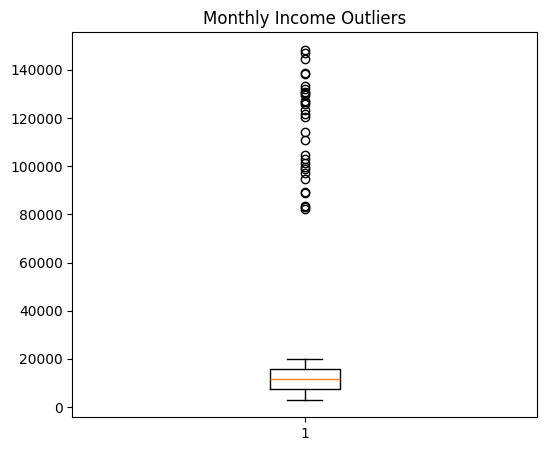

In [18]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['MonthlyIncome'])
plt.title('Monthly Income Outliers')
plt.show()

## IQR

In [19]:
q1 = df['MonthlyIncome'].quantile(0.25)
q3 = df['MonthlyIncome'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df = df[(df['MonthlyIncome'] >= lower) & (df['MonthlyIncome'] <= upper)]
df.reset_index(drop=True, inplace=True)
df.shape

(2970, 7)

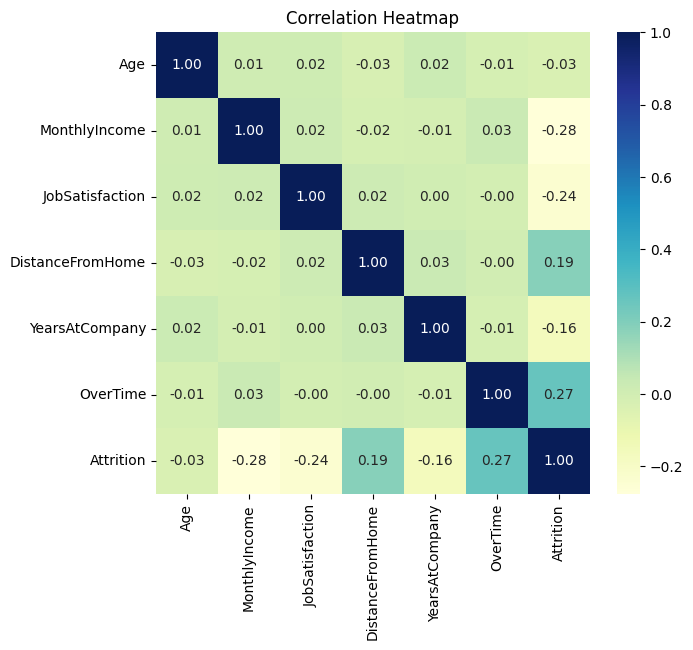

In [20]:
plt.figure(figsize=(7, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Correlation Heatmap')
plt.show()

# Split data

In [21]:
X = df.drop('Attrition', axis=1)
y = df[['Attrition']]
y.value_counts()

Attrition
0            2769
1             201
Name: count, dtype: int64

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=100, stratify=y)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (2376, 6)  y_train =  (2376, 1)
X_test  =  (594, 6)  y_test  =  (594, 1)


# Scaling

In [23]:
from sklearn.preprocessing import MinMaxScaler

my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

# Models

## Logistic Regression

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, model.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Train accuracy: 0.9781144781144782
Test accuracy: 0.9781144781144782
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       554
           1       1.00      0.68      0.81        40

    accuracy                           0.98       594
   macro avg       0.99      0.84      0.90       594
weighted avg       0.98      0.98      0.98       594



## KNN

In [25]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, knn.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Train accuracy: 0.9827441077441077
Test accuracy: 0.9730639730639731
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       554
           1       0.90      0.68      0.77        40

    accuracy                           0.97       594
   macro avg       0.94      0.83      0.88       594
weighted avg       0.97      0.97      0.97       594



## Naive Bayes

In [26]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, gnb.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_gnb))
print(classification_report(y_test, y_pred_gnb))

Train accuracy: 0.9646464646464646
Test accuracy: 0.9579124579124579
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       554
           1       1.00      0.38      0.55        40

    accuracy                           0.96       594
   macro avg       0.98      0.69      0.76       594
weighted avg       0.96      0.96      0.95       594



## SVC

In [27]:
from sklearn.svm import SVC

svc = SVC(C=0.1, kernel='linear', gamma='auto')
svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, svc.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

Train accuracy: 0.9566498316498316
Test accuracy: 0.9579124579124579
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       554
           1       1.00      0.38      0.55        40

    accuracy                           0.96       594
   macro avg       0.98      0.69      0.76       594
weighted avg       0.96      0.96      0.95       594



## Decision Tree

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=100)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, dt.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Train accuracy: 0.976010101010101
Test accuracy: 0.9612794612794613
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       554
           1       0.81      0.55      0.66        40

    accuracy                           0.96       594
   macro avg       0.89      0.77      0.82       594
weighted avg       0.96      0.96      0.96       594



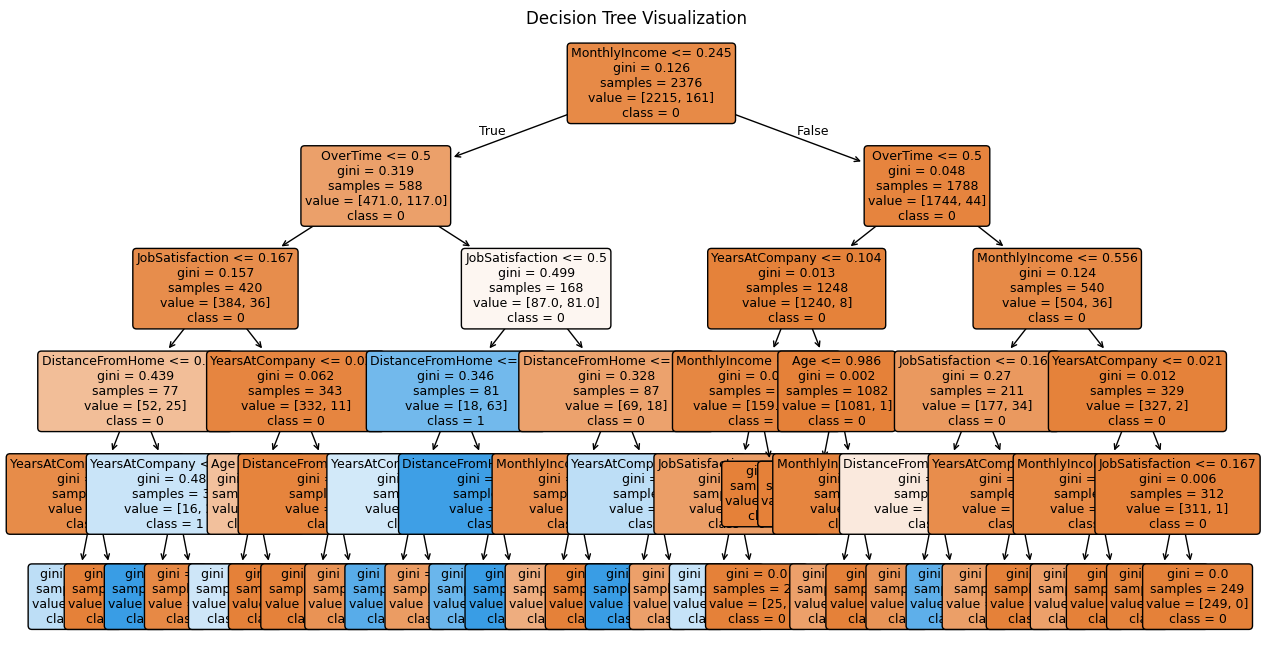

In [29]:
plt.figure(figsize=(15, 8))
plot_tree(dt, feature_names=X.columns.tolist(), class_names=[str(c) for c in dt.classes_], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Visualization')
plt.show()

## GridSearchCV (Decision Tree)

In [30]:
from sklearn.model_selection import GridSearchCV

grid_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

grid = GridSearchCV(estimator=DecisionTreeClassifier(random_state=100), param_grid=grid_params, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(grid.best_params_)
y_pred_best = best_model.predict(X_test)
print('Test accuracy:', accuracy_score(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 5, 'min_samples_split': 2}
Test accuracy: 0.9646464646464646
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       554
           1       0.83      0.60      0.70        40

    accuracy                           0.96       594
   macro avg       0.90      0.80      0.84       594
weighted avg       0.96      0.96      0.96       594



## Random Forest

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print('Train accuracy:', accuracy_score(y_train, rf.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Train accuracy: 1.0
Test accuracy: 0.968013468013468
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       554
           1       0.92      0.57      0.71        40

    accuracy                           0.97       594
   macro avg       0.95      0.79      0.85       594
weighted avg       0.97      0.97      0.96       594



## Models comparison

Naive Bayes             0.957912
SVC                     0.957912
Decision Tree           0.961279
Decision Tree (Grid)    0.964646
Random Forest           0.968013
KNN                     0.973064
Logistic Regression     0.978114
dtype: float64

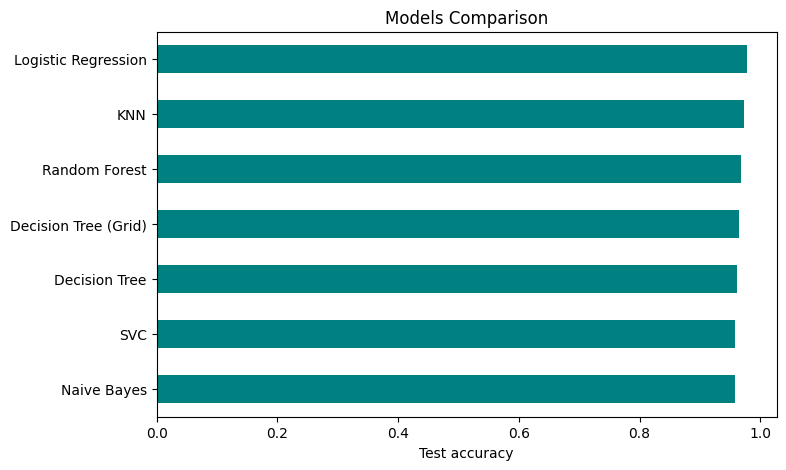

In [32]:
results = {
    'Logistic Regression': accuracy_score(y_test, y_pred),
    'KNN': accuracy_score(y_test, y_pred_knn),
    'Naive Bayes': accuracy_score(y_test, y_pred_gnb),
    'SVC': accuracy_score(y_test, y_pred_svc),
    'Decision Tree': accuracy_score(y_test, y_pred_dt),
    'Decision Tree (Grid)': accuracy_score(y_test, y_pred_best),
    'Random Forest': accuracy_score(y_test, y_pred_rf),
}
results = pd.Series(results).sort_values()
print(results)

plt.figure(figsize=(8, 5))
results.plot(kind='barh', color='teal')
plt.xlabel('Test accuracy')
plt.title('Models Comparison')
plt.show()

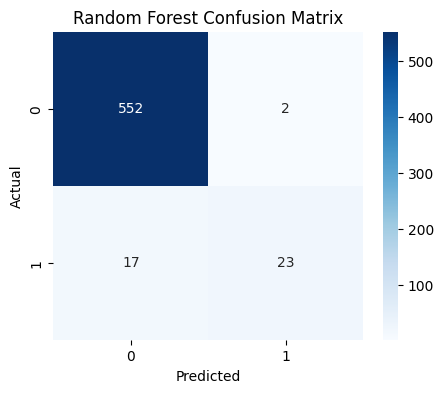

In [33]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()